# 04 · Why do the evaluators report different support levels?

**Objective.** Investigate whether BACE's lower native scores reflect loss or
alteration of evidence, construction of target claims, or support-judgment
rules. No evaluator is assumed to be correct. Support is relative to the
supplied evidence, not external truth, legal compliance or disclosure completeness.

**Reading route:** verified cohort → arithmetic sensitivities → candidate sets
→ claim-count controls → identical-wording judgments → source-linked examples
→ independent-review requirements → controlled prompt sensitivity.

This notebook executes the diagnostics supported by saved artifacts and adds
company-aware uncertainty. Independent evidence-loss rates, semantic coverage,
and independently validated temporal-rule effects remain **COMPUTATION_PENDING**.
Section 9 reads the separately executed support-prompt experiment and reports
its actual readiness. This notebook makes no model/API calls and creates no
human labels. These analyses were designed after the main experiment and are
not preregistered.

Each figure includes its question, source data, interpretation and specific
limits. A code-hidden HTML reading copy accompanies the executed notebook.

In [1]:
from pathlib import Path
import os, sys
analysis_dir = Path.cwd()
if not (analysis_dir / 'evaluator_gap_analysis.py').exists():
    analysis_dir = analysis_dir / 'BACE' / 'analysis'
assert (analysis_dir / 'evaluator_gap_analysis.py').exists(), 'Run from the repository root or BACE/analysis.'
sys.dont_write_bytecode = True
sys.path.insert(0, str(analysis_dir))
runtime = analysis_dir / 'outputs' / 'evaluator_gap' / '.runtime'
os.environ['MPLCONFIGDIR'] = str(runtime / 'matplotlib')
import pandas as pd
from IPython.display import display, Markdown
from evaluator_gap_analysis import (load_inputs, compute_statistics, create_review_templates,
    finalize_provenance, OUT, ROOT, PAPER, SEED, DRAWS, sha, save_json)
from evaluator_gap_figures import (plot_sensitivity, plot_candidates, plot_inventory, plot_literal, note)
pd.set_option('display.max_colwidth', 100)

def estimates(frame, label):
    result = frame[[label, 'estimate', 'low', 'high', 'companies_with_observations', 'denominator']].copy()
    for column in ['estimate', 'low', 'high']:
        result[column] = (100 * result[column]).round(2)
    return result.rename(columns={'estimate':'Estimate (%) or difference (pp)', 'low':'95% interval: lower',
        'high':'95% interval: upper', 'companies_with_observations':'Companies', 'denominator':'Units'})

## 1. Which records are compared, and what has been verified?

The original analysis snapshot is read without regeneration. The earlier
paper-level diagnostic tables are reused as hash-verified derived inputs and
reconciled against claim-level records. New results have a separate output
directory; no earlier notebooks or outputs are overwritten.

An incomplete BACE result remains missing. A literal match belongs to the same
disclosure and requires a unique complete string after casefolding and whitespace
normalization. It is not a human semantic alignment or a reference label.

In [2]:
data = load_inputs()
display(data['cohorts'])
case, claims, pairs = data['case'], data['claims'], data['pairs']
note(f"**Verified data:** {len(case):,} paired disclosures, {case.company_id.nunique()} companies, "
     f"{len(claims):,} BACE target claims, and {len(pairs):,} unique literal BACE–RAGAS pairs. "
     f"The literal pairs cover {100 * len(pairs) / len(claims):.2f}% of BACE DCs. "
     "Snapshot hashes, native arithmetic and consumed example source hashes passed. "
     "The entire raw-call history and extraction lineage were not re-audited.")
display(pd.read_csv(OUT / 'tables' / 'excluded_cases.csv'))

,cohort,disclosures,companies
0,Planned,1800,30
1,Paired completed,1798,30
2,At least one literal pair,1454,30


**Verified data:** 1,798 paired disclosures, 30 companies, 94,955 BACE target claims, and 5,709 unique literal BACE–RAGAS pairs. The literal pairs cover 6.01% of BACE DCs. Snapshot hashes, native arithmetic and consumed example source hashes passed. The entire raw-call history and extraction lineage were not re-audited.

,generation_case_id,company_name,year,task,state_status
0,w2__text_embedding_3_large__stratified_by_evidence_type_n10__banco_bpm__2019__s1_5_workforce_tar...,Banco BPM,2019,S1-5,partial
1,w2__text_embedding_3_large__stratified_by_evidence_type_n10__investec__2023__s1_1_workforce_poli...,Investec,2023,S1-1,partial


### Statistical definitions

The primary native score gives each disclosure equal weight. Literal-pair
pooled rates give each matched target equal weight; an accompanying case-macro
sensitivity gives each disclosure with a match equal weight. These estimands
are never interchanged.

Where shown, 95% percentile intervals resample complete company clusters with
replacement, retaining every record and method pairing in each selected
company. There are 2,000 draws with seed 20260921. The same resamples are used
for all conditions. Subgroup ratios include the full common-cohort company
universe, with zero contributions from companies outside that subgroup.

These intervals describe resampling of the observed companies. They are not
design-adjusted estimates for all companies in the source register and do not
include model-run, annotation or missing-case uncertainty. No significance
tests, p-values or causal attribution are reported. Leave-one-company-out
ranges provide an additional descriptive influence check.

In [3]:
tables = compute_statistics(data)
display(tables['analysis_readiness'])

,analysis,status,required_evidence,interpretation_boundary
0,Native paired scores and arithmetic sensitivities,COMPUTED_VERIFIED,Saved scores and claim counts,Operational score differences
1,Candidate-set and literal-pair diagnostics,COMPUTED_VERIFIED,"Saved claims, selected sets and verdicts",Information paths and selected disagreements
2,Full-source / full-EC / candidate-EC loss rates,COMPUTATION_PENDING,Independent source-linked sufficiency labels,Cannot be inferred from candidate counts
3,Neutral proposition coverage and semantic alignment,COMPUTATION_PENDING,Independent passage inventory and mapping,Literal pairs do not establish global coverage
4,Temporal and inference-rule interactions,COMPUTATION_PENDING,Independent temporal/rule labels on shared targets,BACE diagnosis labels cannot supply independent mechanisms
5,Controlled evidence / inventory / judge conditions,COMPUTATION_PENDING,Explicitly defined additional evaluations,No model calls in this notebook


## 2. Can denominator treatment or completely empty candidate sets explain the gap?

Two precisely defined arithmetic sensitivities are evaluated. The first
removes only BACE-unsupported DCs diagnosed as `non_disclosure_statement`.
The second hypothetically changes every zero-candidate DC to supported.
Neither is a model rerun, independently justified correction, or proposed
replacement for the primary score. Their subsets overlap.

**Figure question.** Can these two specified arithmetic changes remove the native score gap?

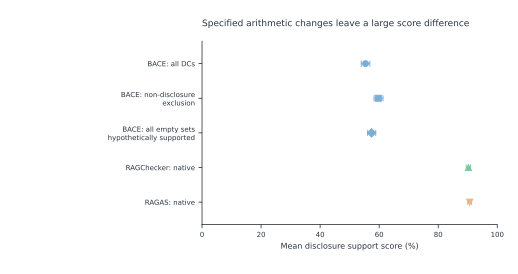

Points are disclosure-macro scores on 1,798 paired cases. Bars are 95% percentile company-cluster intervals (2,000 draws; seed 20260921). The two sensitivity conditions change only BACE and are not model reruns.

[PDF](outputs/evaluator_gap/figures/04_score_sensitivity.pdf) · [SVG](outputs/evaluator_gap/figures/04_score_sensitivity.svg) · [PNG](outputs/evaluator_gap/figures/04_score_sensitivity.png) · [Source data](outputs/evaluator_gap/figures/04_score_sensitivity__data.csv)

**Pattern and evidence.** BACE's native mean is 55.4% (95% interval 53.9–56.8%). Removing its unsupported non-disclosure statements gives 59.7% (95% interval 58.3–61.3%), a paired increase of 4.35 points. Relabelling every zero-candidate DC supported gives 57.4% (95% interval 56.1–58.8%), an increase of 2.05 points. Native comparator means remain 90.2% and 90.7%.

**Interpretation.** Neither specified arithmetic condition eliminates the difference. They narrow two simple explanations without establishing the source of the remaining disagreement.

**Limits.** Non-disclosure exclusion changes the denominator and removes only BACE-unsupported statements with that diagnosis. The empty-set condition is an extreme bound for that subset alone, not an accuracy correction or a bound for all upstream losses. The conditions overlap and must not be added. Native target inventories remain different.

,contrast,Estimate (%) or difference (pp),95% interval: lower,95% interval: upper,Companies,Units
0,Non-disclosure exclusion minus all-DC BACE,4.35,3.84,4.91,30,1798.0
1,All empty sets supported minus all-DC BACE,2.05,1.65,2.47,30,1798.0
2,BACE minus RAGChecker,-34.86,-36.17,-33.46,30,1798.0
3,BACE minus RAGAS,-35.28,-36.50,-34.05,30,1798.0
4,Non-disclosure exclusion minus RAGChecker,-30.51,-32.07,-28.81,30,1798.0
5,Non-disclosure exclusion minus RAGAS,-30.94,-32.30,-29.48,30,1798.0


In [4]:
plot_sensitivity(tables)
display(estimates(tables['paired_effects'], 'contrast'))

## 3. What do candidate sets reveal about possible evidence loss?

Candidate counts can identify an empty-set bottleneck. They cannot establish
whether a nonempty set contains the required premise or preserves its scope.
The distribution below therefore diagnoses pipeline structure rather than
candidate recall or evaluator correctness.

**Figure question.** Does complete candidate absence describe most BACE rejections?

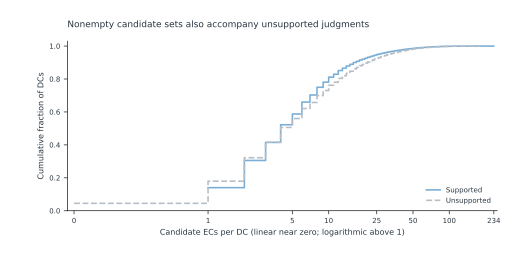

ECDFs use all saved BACE DCs, separated by their saved support labels. Every observation contributes; no thinning or smoothing is applied. These are finite-cohort distributions without uncertainty bands. The axis retains zero explicitly.

[PDF](outputs/evaluator_gap/figures/04_candidate_sets.pdf) · [SVG](outputs/evaluator_gap/figures/04_candidate_sets.svg) · [PNG](outputs/evaluator_gap/figures/04_candidate_sets.png) · [Source data](outputs/evaluator_gap/figures/04_candidate_sets__data.csv)

**Pattern and evidence.** There are 1,911 zero-candidate DCs among 94,955 DCs, or 4.48% of the 42,646 unsupported DCs. All zero-candidate cases are unsupported by the pipeline's deterministic rule. Both groups also contain nonempty candidate sets.

**Interpretation.** Completely empty sets are a limited subset of the rejections. The presence of candidate evidence is not evidence that the decisive premise was extracted or selected.

**Limits.** Candidate count measures inventory size, not relevance, sufficiency or recall. The labels on the curves are automated outcomes, not independent reference judgments. Missing qualifiers inside nonempty sets remain unmeasured.

,label,claims,zero_candidates,median_candidates,max_candidates,zero_candidate_percent
0,direct,34430,0,3.0,234,0.00
1,inferred,17879,0,7.0,191,0.00
2,non_disclosure_statement,6378,985,4.0,107,15.44
3,contradiction,42,0,6.0,43,0.00
4,evidence_conflation,12205,0,9.0,178,0.00
5,factual_boundary_distortion,19130,0,3.0,176,0.00
6,inferential_inflation,3193,0,6.0,170,0.00
7,unsupported_novelty,1698,926,0.0,121,54.53


In [5]:
plot_candidates(tables)
candidate_summary = tables['candidate_sets'].copy()
candidate_summary['zero_candidate_percent'] = (100 * candidate_summary.pop('zero_candidate_fraction')).round(2)
display(candidate_summary)

## 4. Is a larger BACE claim count necessary for lower scores?

We condition on whether BACE's native inventory is larger, equal, or no larger
than the comparator's. This is a descriptive control for claim count, not a
semantic control for which propositions were extracted. Equal-count cases
are part of the no-greater group and are shown as a nested sensitivity.

**Figure question.** Does the score difference disappear when BACE extracts no more claims than the comparator?

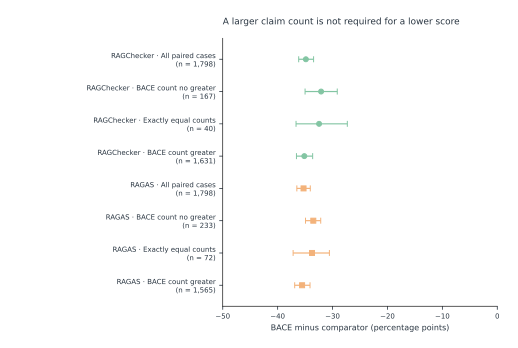

Points show disclosure-macro paired differences within each named count-defined subset. Bars use the same company-cluster bootstrap as the main sensitivity analysis. Equal-count cases are nested within the no-greater subset; these rows are not mutually exclusive samples.

[PDF](outputs/evaluator_gap/figures/04_inventory_groups.pdf) · [SVG](outputs/evaluator_gap/figures/04_inventory_groups.svg) · [PNG](outputs/evaluator_gap/figures/04_inventory_groups.png) · [Source data](outputs/evaluator_gap/figures/04_inventory_groups__data.csv)

**Pattern and evidence.** When BACE has no more claims, its score remains 32.09 points lower than RAGChecker in 167 cases and 33.51 points lower than RAGAS in 233 cases. Exactly equal counts also retain negative mean differences.

**Interpretation.** More BACE claims are not necessary for the observed direction of the gap. Counting claims alone is insufficient to explain the comparison.

**Limits.** Equal counts do not mean equal propositions. These outcome-defined subsets are selected, and their intervals do not identify a causal effect of claim splitting or omission. All comparisons remain native judgments.

,comparison,Estimate (%) or difference (pp),95% interval: lower,95% interval: upper,Companies,Units
0,ragchecker / All paired cases,-34.86,-36.17,-33.46,30,1798.0
1,ragchecker / BACE count no greater,-32.09,-35.01,-29.14,30,167.0
2,ragchecker / Exactly equal counts,-32.45,-36.65,-27.31,23,40.0
3,ragchecker / BACE count greater,-35.14,-36.57,-33.62,30,1631.0
4,ragas / All paired cases,-35.28,-36.50,-34.05,30,1798.0
5,ragas / BACE count no greater,-33.51,-34.93,-32.16,30,233.0
6,ragas / Exactly equal counts,-33.74,-37.18,-30.58,27,72.0
7,ragas / BACE count greater,-35.55,-36.90,-34.11,30,1565.0


In [6]:
plot_inventory(tables)
inventory_intervals = estimates(tables['inventory_groups'].assign(
    comparison=lambda d: d.method + ' / ' + d.group), 'comparison')
display(inventory_intervals)

## 5. Do identical target words receive identical judgments?

Each matched row is a target assertion extracted from the generated disclosure.
Evidence is supposed to support that target. The pairing was performed after
native evaluation; the evaluators were not rerun on a newly standardized
input. BACE still used selected ECs while RAGAS used all supplied cards.

No unique literal RAGChecker partners were found by the existing matching
rule. Its joined-triplet representation requires semantic mapping for a
meaningful shared-proposition comparison. Zero string matches do not imply
zero semantic overlap.

**Figure question.** What happens when both methods extracted the same target wording?

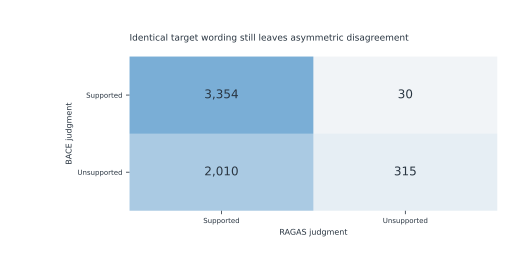

Cells count unique case-specific literal matches after casefolding and whitespace normalization. The axes are two automated judgments, not prediction and ground truth. Counts are exact for this subset; uncertainty for its pooled rates and paired difference is reported in the accompanying table.

[PDF](outputs/evaluator_gap/figures/04_literal_pairs.pdf) · [SVG](outputs/evaluator_gap/figures/04_literal_pairs.svg) · [PNG](outputs/evaluator_gap/figures/04_literal_pairs.png) · [Source data](outputs/evaluator_gap/figures/04_literal_pairs__data.csv)

**Pattern and evidence.** The 5,709 pairs contain 2,010 BACE-unsupported/RAGAS-supported decisions and 30 opposite decisions. Pooled support is 59.3% (95% interval 57.3–61.5%) for BACE and 94.0% (95% interval 93.0–94.8%) for RAGAS. Their paired pooled difference is -34.68 points (95% interval -36.72 to -32.31).

**Interpretation.** Different target wording cannot account for these specific paired verdicts. Evidence representation, the context accompanying that wording, and judgment procedures remain different.

**Limits.** Only about 6% of BACE DCs have these literal partners, so neither the support levels nor disagreement proportions represent all claims. RAGChecker's absence of literal matches is a representation issue, not absence of semantic overlap. No accuracy or independent mechanism label is established.

,quantity,Estimate (%) or difference (pp),95% interval: lower,95% interval: upper,Companies,Units
0,BACE support,59.27,57.31,61.51,30,5709.0
1,RAGAS support,93.96,93.02,94.82,30,5709.0
2,BACE minus RAGAS,-34.68,-36.72,-32.31,30,5709.0
3,Binary agreement,64.27,62.25,66.60,30,5709.0


In [7]:
plot_literal(tables)
display(estimates(tables['literal_pooled_estimates'], 'quantity'))

### Does changing the weighting or removing one company change the reading?

The first table below averages scores within each matched disclosure before
averaging across disclosures. It includes only disclosures with at least one
literal pair. It does not recover the native full-inventory macro score.

The second table removes each company in turn. These are influence ranges,
not confidence intervals and not independent replication. A stable range
does not repair the selection bias of literal matching.

In [8]:
display(estimates(tables['literal_case_estimates'], 'quantity'))
influence = pd.concat([
    tables['paired_effects'].loc[tables['paired_effects'].contrast.isin(['BACE minus RAGChecker', 'BACE minus RAGAS'])]
        .rename(columns={'contrast':'quantity'}),
    tables['literal_pooled_estimates'].loc[tables['literal_pooled_estimates'].quantity.eq('BACE minus RAGAS')]
        .assign(quantity='Literal pairs: BACE minus RAGAS')], ignore_index=True)
influence = influence[['quantity','estimate','leave_one_company_out_min','leave_one_company_out_max']].copy()
influence.iloc[:,1:] = (100 * influence.iloc[:,1:]).round(2)
display(influence.rename(columns={'estimate':'Paired difference (pp)',
    'leave_one_company_out_min':'Leave-one-company-out minimum (pp)',
    'leave_one_company_out_max':'Leave-one-company-out maximum (pp)'}))

,quantity,Estimate (%) or difference (pp),95% interval: lower,95% interval: upper,Companies,Units
0,bace,62.48,60.30,64.91,30,1454.0
1,ragas,94.23,93.27,95.11,30,1454.0
2,difference,-31.75,-34.08,-29.17,30,1454.0


,quantity,Paired difference (pp),Leave-one-company-out minimum (pp),Leave-one-company-out maximum (pp)
0,BACE minus RAGChecker,-34.86,-35.14,-34.57
1,BACE minus RAGAS,-35.28,-35.55,-35.07
2,Literal pairs: BACE minus RAGAS,-34.68,-35.30,-34.28


### What are BACE's own diagnoses within the selected disagreements?

The next counts are saved automated diagnoses among BACE-unsupported /
RAGAS-supported literal pairs. They identify records to inspect. They do not
establish the prevalence of independently confirmed failure mechanisms.
In particular, `factual_boundary_distortion` is not an independently measured
temporal category.

In [9]:
diagnoses = tables['literal_disagreement_diagnoses'].copy()
diagnoses['percent_of_selected_disagreements'] = (100 * diagnoses.pop('fraction_of_selected_disagreements')).round(2)
display(diagnoses)

,bace_label,pairs,percent_of_selected_disagreements
0,non_disclosure_statement,52,2.59
1,contradiction,0,0.00
2,evidence_conflation,283,14.08
3,factual_boundary_distortion,1419,70.60
4,inferential_inflation,156,7.76
5,unsupported_novelty,100,4.98


## 6. What evidence does RAGAS accept in concrete matched claims?

These fixed illustrations were selected for the earlier discussion from the
first company in the sorted literal-pair file. They are neither random nor
representative, and they do not estimate mechanism frequencies. Both
agreement and disagreement examples are retained. Original generated passages,
all input cards, full EC inventories and selected ECs are preserved in the
[source bundle](../../paper/analysis/evaluator_gap/literal_examples.json).

A later BACE diagnosis is not an independent account of why the earlier
support stage made its decision.

In [10]:
qualifications = [
    'The supplied table gives the 2017 count and BACE also supports it. Reporting coverage remains a separate qualifier.',
    'RAGAS cites the environmental-obligation wording; BACE questions extension of a 2016 report statement to the 2019 context. The continuity rule needs independent review.',
    'The supplied 2018 social-scope footnote names HOP!, whereas BACE has no candidate ECs. This establishes an information-path difference; source scope and target-year applicability remain unresolved.',
    'RAGAS reads new training-access methods as broadened access. Candidate ECs retain the new methods, but BACE questions the stronger characterization. This is a proposed rule-sensitive example, not an adjudicated error.',
    'The source describes prospective expenditure under a discipline framework in 2015. BACE questions both the temporal extension and the claim of actual management in the 2019 context.'
]
for example, qualification in zip(data['examples']['examples'], qualifications):
    native = example['ragas_claim']
    diagnosis = example['bace_diagnosis']
    bace_text = diagnosis['rationale'] if diagnosis else 'Saved supported judgment; no unsupported diagnosis.'
    note('**Target:** ' + example['pair']['bace_dc_text'] + '\n\n'
         '**RAGAS saved reason:** ' + native['reason'] + '\n\n'
         '**BACE candidate ECs:** ' + str(len(example['candidate_ecs'])) + '. **Later diagnosis:** ' + bace_text + '\n\n'
         '**Source-inspection limit:** ' + qualification)

**Target:** KLM subsidiaries recorded 53 workplace accidents in 2017.

**RAGAS saved reason:** Evidence 8 lists 53 total workplace accidents for KLM subsidiaries in 2017.

**BACE candidate ECs:** 2. **Later diagnosis:** Saved supported judgment; no unsupported diagnosis.

**Source-inspection limit:** The supplied table gives the 2017 count and BACE also supports it. Reporting coverage remains a separate qualifier.

**Target:** Air France-KLM incorporates environmental obligations into relevant product or service specifications.

**RAGAS saved reason:** Evidence 10 states that suppliers' environmental obligations are stipulated in product or service specifications.

**BACE candidate ECs:** 1. **Later diagnosis:** The evidence establishes that suppliers’ environmental obligations were stipulated in product or service specifications in 2016, but it does not establish the same practice for the 2019 reporting year.

**Source-inspection limit:** RAGAS cites the environmental-obligation wording; BACE questions extension of a 2016 report statement to the 2019 context. The continuity rule needs independent review.

**Target:** Social reporting covers HOP!.

**RAGAS saved reason:** The stated social reporting scope explicitly includes HOP!.

**BACE candidate ECs:** 0. **Later diagnosis:** No evidence establishes that social reporting covers HOP!.

**Source-inspection limit:** The supplied 2018 social-scope footnote names HOP!, whereas BACE has no candidate ECs. This establishes an information-path difference; source scope and target-year applicability remain unresolved.

**Target:** Air France broadened access to training through Manager Cafés.

**RAGAS saved reason:** Manager Cafes are explicitly listed among the new training-access methods.

**BACE candidate ECs:** 2. **Later diagnosis:** The evidence establishes that Manager Cafés were included in new conditions for training access, but it does not establish that they broadened access to training.

**Source-inspection limit:** RAGAS reads new training-access methods as broadened access. Candidate ECs retain the new methods, but BACE questions the stronger characterization. This is a proposed rule-sensitive example, not an adjudicated error.

**Target:** Air France-KLM manages fleet capital expenditure under strict capital discipline.

**RAGAS saved reason:** Evidence 7 explicitly states that fleet capital expenditure would be undertaken within a framework of strict capital-expenditure discipline.

**BACE candidate ECs:** 2. **Later diagnosis:** The evidence describes a 2015 plan to increase fleet capital expenditure within a strict discipline framework, not Air France-KLM’s actual management of fleet capital expenditure in 2019.

**Source-inspection limit:** The source describes prospective expenditure under a discipline framework in 2015. BACE questions both the temporal extension and the claim of actual management in the 2019 context.

**Evonik correction.** The previously discussed emissions-total example is
not a confirmed BACE false rejection. The actual supplied table contains the
number but omits complete unit/column context. The later contradiction
rationale remains questionable, but this does not establish that the binary
unsupported decision was wrong. See the
[input-boundary recheck](../../paper/analysis/evaluator_gap/evonik_boundary_recheck.json).

## 7. Independent evidence-chain analysis — COMPUTATION_PENDING

For each sampled target, first verify its fidelity to the generated passage.
Then independently judge sufficiency against (R) all original prompt-visible
cards, (E) the full EC inventory, and (C) the candidate ECs. Add pre-dedup ECs
if extraction and deduplication losses need separate estimates. Preserve
source locators, sufficient premise sets, ambiguity and initial reviewer labels.

The principal quantity is the fraction of BACE rejections that full-source
review supports: `count(B = unsupported and R = supported) / count(B = unsupported)`,
using design weights when sampled. Stage-specific loss rates condition on
sufficient support at the preceding stage; their denominators differ and
they cannot be added. Audit accepted claims too, to detect spurious support
and estimate any net reassessment of the score.

The existing candidate-only reviewer packets supply neither R nor E. Their
400 primary and 200 enriched supplementary units must not be pooled
unweighted. Full-source review added to the primary sample could address
BACE-inventory questions, but would still not validate extraction coverage.

No empty plot or zero-valued loss estimate is displayed for these missing data.

## 8. Claim construction and inference rules — COMPUTATION_PENDING

Build a neutral proposition inventory from probability-sampled generated
passages. Map each native inventory to it, preserving one-to-one and
split/merged relations, omissions and added qualifiers. Do not propagate an
unsupported conjunction to every component.

With fixed evidence, a common judgment procedure applied to different target
inventories can describe construction effects. With fixed targets and
evidence, different explicitly adapted judgment procedures can describe
procedure effects. A crossed design additionally estimates their interaction.
Such conditions are additional experiments, not unchanged native scores;
none is run by this notebook.

Independently annotate whether the target requires temporal carry-forward,
its asserted period and relevant evidence period. Do not infer this solely
from BACE diagnoses or the oldest card in the prompt. Paired method gaps can
then be compared between temporal and non-temporal targets. Strict-period
and explicitly defined continuity rules can be assessed on the same claims;
relaxing a rule changes the support construct and does not prove a prior
error. Ordinary independent-claim tests would ignore company dependence.

The complete estimands, sampling limits and controlled-condition design are in
the [statistical analysis plan](../../paper/analysis/evaluator_gap/statistical_analysis_plan.md).

In [11]:
review_templates = create_review_templates()
display(review_templates)
note('**These are header-only schemas.** They are not sampled reviewer packets or completed human annotations. '
     'Existing files are never overwritten, and no template data are treated as a reference automatically. '
     '[Review schema guide](outputs/evaluator_gap/review_templates/README.md).')

,template,columns,status
0,evidence_chain_review,15,COMPUTATION_PENDING
1,proposition_alignment,11,COMPUTATION_PENDING
2,temporal_rule_review,13,COMPUTATION_PENDING


**These are header-only schemas.** They are not sampled reviewer packets or completed human annotations. Existing files are never overwritten, and no template data are treated as a reference automatically. [Review schema guide](outputs/evaluator_gap/review_templates/README.md).

## 9. How sensitive is BACE to its support-judgment instructions?

The author-authorized experiment fixes every BACE DC, its ordered candidate
ECs, company and reporting year, model request settings, message roles, JSON
schema and native parser. It changes only the support-judgment instructions
and criteria. **BACE–RAGAS-style** and **BACE–RAGChecker-style** retain BACE's
support-set output task and are not native baseline evaluations.

The [frozen protocol](../experiments/prompt_sensitivity_v1/PROTOCOL.md),
[input and sampling plan](../experiments/prompt_sensitivity_v1/plan.json),
[RAGAS-style prompt](../experiments/prompt_sensitivity_v1/prompts/ragas_style_v1.txt)
and [RAGChecker-style prompt](../experiments/prompt_sensitivity_v1/prompts/ragchecker_style_v1.txt)
were saved before the first new model call. The original-to-adapted diffs
record both the native criterion and the changes needed for BACE compatibility.

Both new conditions keep the same output contract and minimality section, and
share descriptive direct/inferred labels. The original strict necessary-inference
restrictions are part of the replaced judgment instructions. The primary
endpoint is whether support_sets is nonempty; inferred-label proportions do
not establish a common strict-inference construct or reasoning ability.

All original claims, including originally supported claims, are replayed.
Empty-candidate jobs remain deterministic unsupported and in the denominator.
Runtime or parsing failures remain missing. Final scores use only disclosures
with every claim complete in all three conditions; the original score is
recomputed on that identical cohort. No final primary estimate is shown while
the full scheduled run is incomplete.

In [12]:
from evaluator_gap_prompt_sensitivity import load_analysis, LABELS as PROMPT_LABELS, DEST as PROMPT_OUT
from evaluator_gap_prompt_figures import plot_prompt_effects, plot_prompt_transitions

def prompt_effect_display(frame):
    if frame.empty:
        return frame
    shown = frame[['condition','disclosures','claims']].copy()
    shown['condition'] = shown.condition.map(PROMPT_LABELS)
    shown['Change (pp, 95% CI)'] = frame.apply(
        lambda r: f'{100*r.estimate:+.2f} [{100*r.low:+.2f}, {100*r.high:+.2f}]', axis=1)
    return shown

prompt_results = load_analysis()
display(prompt_results['completeness'])
if not prompt_results['ready']:
    note('**COMPUTATION_PENDING — prompt sensitivity.** Current saved run status: '
         + prompt_results['status'] + '. Full-cohort support estimates and figures are withheld. '
         'The notebook reads saved results only; it does not launch or resume model calls.')
else:
    note('**COMPUTED_VERIFIED — paired prompt sensitivity.** All scheduled jobs have a recorded outcome. '
         'Failed jobs remain missing and incomplete disclosures are excluded as whole units. '
         'Counts below identify the exact analyzed cohort.')

,condition,planned_claims,recorded_claims,valid_claims,failed_claims,pending_claims
0,ragas_style,94955,94955,94953,2,0
1,ragchecker_style,94955,94955,94954,1,0
2,original_repeat,3106,3106,3106,0,0


**COMPUTED_VERIFIED — paired prompt sensitivity.** All scheduled jobs have a recorded outcome. Failed jobs remain missing and incomplete disclosures are excluded as whole units. Counts below identify the exact analyzed cohort.

### Support-rate changes and individual transitions

The main table averages support rates over complete paired disclosures.
Intervals resample company clusters using the same 2,000 draws and seed as
the earlier sections. Effect units are percentage points, not relative percent
changes. The two transition panels instead pool claim counts and display
percentages conditional on the original judgment in each row.

Company bootstrap intervals condition on the observed runs. They do not
measure independent model-run variance or establish correctness. Native RAGAS
and RAGChecker scores are background comparisons with different inventories;
they are not additional rows in this controlled experiment.

,condition,planned_disclosures,complete_disclosures,incomplete_disclosures
0,ragas_style,1798,1796,2
1,ragchecker_style,1798,1797,1
2,original_repeat,60,60,0


**Recorded failures remain missing.** A failed full-condition claim excludes its entire disclosure from the primary paired analysis. A failed repeat-control claim excludes its disclosure from the repeat comparison. [Failure details and record hashes](outputs/evaluator_gap/prompt_sensitivity/tables/failed_records.csv).

,condition,generation_case_id,dc_id,call_status,output_attempts,validation_error,error_type
0,ragas_style,w2__text_embedding_3_large__stratified_by_evidence_type_n10__intertek__2019__s1_5_workforce_targets,dc_9f3259b777d6b37282fa2545129e764d,invalid_output,3,"Support set ['ec_011', 'ec_078', 'ec_093'] is a strict superset of ['ec_093'] and is therefore n...",None
1,ragas_style,w2__text_embedding_3_large__stratified_by_evidence_type_n10__hera__2022__e1_4_targets,dc_51f32275f53ab791d0c325a5da7a0c12,invalid_output,3,Support set 1 contains unknown EC IDs: ['ec_078'],None
2,ragchecker_style,w2__text_embedding_3_large__stratified_by_evidence_type_n10__intertek__2019__s1_5_workforce_targets,dc_9f3259b777d6b37282fa2545129e764d,invalid_output,3,"Support set ['ec_011', 'ec_078', 'ec_093'] is a strict superset of ['ec_093'] and is therefore n...",None


,label,disclosures,claims,"Mean support (%, 95% CI)","Change (pp, 95% CI)"
0,Original BACE,1796,94854,"55.36 [53.91, 56.83]",Reference
1,BACE–RAGAS-style,1796,94854,"63.02 [61.16, 64.92]","+7.66 [+6.84, +8.46]"
2,BACE–RAGChecker-style,1796,94854,"60.34 [58.47, 62.22]","+4.97 [+4.14, +5.79]"


**Figure question.** How much does changing judgment instructions change BACE support rates?

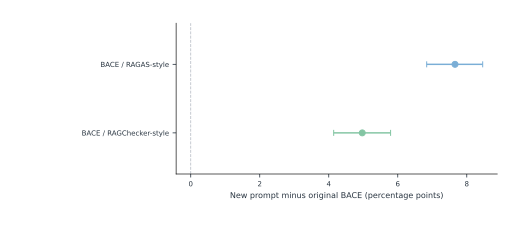

Paired disclosure-macro changes on 1,796 complete disclosures. Points are mean differences; bars are 95% company-cluster percentile intervals (2,000 draws). The zero line denotes no net change.

[PDF](outputs/evaluator_gap/figures/04_prompt_sensitivity_effects.pdf) · [SVG](outputs/evaluator_gap/figures/04_prompt_sensitivity_effects.svg) · [PNG](outputs/evaluator_gap/figures/04_prompt_sensitivity_effects.png) · [Source data](outputs/evaluator_gap/figures/04_prompt_sensitivity_effects__data.csv)

**Pattern and evidence.** BACE–RAGAS-style: +7.66 pp (95% CI +6.84 to +8.46); BACE–RAGChecker-style: +4.97 pp (95% CI +4.14 to +5.79).

**Interpretation.** Targets, candidate evidence, metadata, model request settings and support-set output are held fixed; judgment instructions differ.

**Limits.** These are adapted BACE conditions, not native baseline scores. Intervals condition on observed runs. A score increase is not evidence of improved accuracy or a causal allocation of the native score gap.

**Figure question.** Which original support judgments change under each prompt?

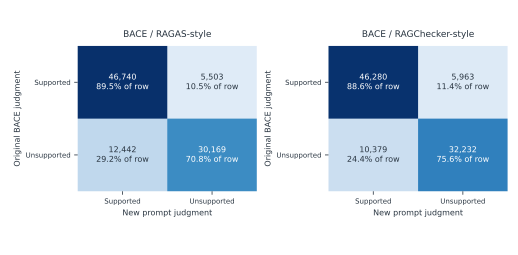

Rows are original BACE judgments and columns are new judgments. Each cell shows a count and its row percentage. Both panels use the same complete paired claim cohort and color scale; this is not a confusion matrix against ground truth.

[PDF](outputs/evaluator_gap/figures/04_prompt_sensitivity_transitions.pdf) · [SVG](outputs/evaluator_gap/figures/04_prompt_sensitivity_transitions.svg) · [PNG](outputs/evaluator_gap/figures/04_prompt_sensitivity_transitions.png) · [Source data](outputs/evaluator_gap/figures/04_prompt_sensitivity_transitions__data.csv)

**Pattern and evidence.** BACE–RAGAS-style, supported → unsupported: 5,503 claims (10.53% of original-status claims); BACE–RAGAS-style, unsupported → supported: 12,442 claims (29.20% of original-status claims); BACE–RAGChecker-style, supported → unsupported: 5,963 claims (11.41% of original-status claims); BACE–RAGChecker-style, unsupported → supported: 10,379 claims (24.36% of original-status claims).

**Interpretation.** Both flip directions are observed so that offsetting changes cannot be hidden by a small net support-rate difference.

**Limits.** Cell counts pool claims, whereas the primary effect gives each disclosure equal weight. Automated disagreement does not identify which judgment is correct.

,condition,original_supported,new_supported,claims,all_claims,original_status_denominator,fraction_all_claims,fraction_original_status
0,ragas_style,True,True,46740,94854,52243,0.492757,0.894665
1,ragas_style,True,False,5503,94854,52243,0.058015,0.105335
2,ragas_style,False,True,12442,94854,42611,0.131170,0.291990
3,ragas_style,False,False,30169,94854,42611,0.318057,0.708010
4,ragchecker_style,True,True,46280,94854,52243,0.487908,0.885860
5,ragchecker_style,True,False,5963,94854,52243,0.062865,0.114140
6,ragchecker_style,False,True,10379,94854,42611,0.109421,0.243576
7,ragchecker_style,False,False,32232,94854,42611,0.339806,0.756424


**Separate pooled estimand:** the following table weights each claim equally. It is not the disclosure-macro primary score.

,condition,supported,claims,support_rate_percent
0,Original BACE,52243,94854,55.08
1,BACE–RAGAS-style,59182,94854,62.39
2,BACE–RAGChecker-style,56659,94854,59.73


In [13]:
if prompt_results['ready']:
    display(prompt_results['disclosure_completeness'])
    if not prompt_results['failed_records'].empty:
        note('**Recorded failures remain missing.** A failed full-condition claim excludes its entire disclosure from the primary paired analysis. '
             'A failed repeat-control claim excludes its disclosure from the repeat comparison. '
             '[Failure details and record hashes](outputs/evaluator_gap/prompt_sensitivity/tables/failed_records.csv).')
        display(prompt_results['failed_records'][['condition','generation_case_id','dc_id',
            'call_status','output_attempts','validation_error','error_type']])
    score_table = prompt_results['scores'].copy()
    effect_index = prompt_results['effects'].set_index('condition')
    score_table['Mean support (%, 95% CI)'] = score_table.apply(
        lambda r: f'{100*r.estimate:.2f} [{100*r.low:.2f}, {100*r.high:.2f}]', axis=1)
    score_table['Change (pp, 95% CI)'] = score_table.condition.map(lambda c: 'Reference' if c == 'original' else
        f'{100*effect_index.loc[c,"estimate"]:+.2f} [{100*effect_index.loc[c,"low"]:+.2f}, {100*effect_index.loc[c,"high"]:+.2f}]')
    display(score_table[['label','disclosures','claims','Mean support (%, 95% CI)','Change (pp, 95% CI)']])
    plot_prompt_effects(prompt_results)
    plot_prompt_transitions(prompt_results)
    display(prompt_results['transitions'])
    note('**Separate pooled estimand:** the following table weights each claim equally. It is not the disclosure-macro primary score.')
    pooled_display = prompt_results['pooled'].copy()
    pooled_display['support_rate_percent'] = (100 * pooled_display.pop('support_rate')).round(2)
    pooled_display['condition'] = pooled_display.condition.map(PROMPT_LABELS)
    display(pooled_display)

### Company influence, overlapping flips and a contemporaneous repeat control

Two disclosures per company were selected by a fixed hash rule before new
outputs were inspected. All their claims are rerun with the original BACE
prompt during the new experiment. This 60-disclosure control compares one
current run with historical BACE; it is not a replicated variance decomposition.
The next table compares all three current conditions with historical BACE
on the same complete repeat subset.

Company-specific effects and leave-one-company-out ranges show concentration
and influence. Ranges are not confidence intervals. The overlap table reports
whether each variant flips the original binary label; if both flip a label,
their new binary direction is necessarily the same.

The directional table separates shared additions to support from shared
removals. Its shared fraction divides the intersection by the union of the
two variants' flipped claims in that direction. It is undefined when neither
variant flips any claim in that direction.

In [14]:
if prompt_results['ready']:
    display(prompt_effect_display(prompt_results['repeat_effects']))
    display(prompt_results['repeat_transitions'])
    display(prompt_results['flip_overlap'])
    directional_display = prompt_results['flip_overlap_by_direction'][['direction',
        'original_status_denominator','ragas_flips','ragchecker_flips','both_flips',
        'union_flips','shared_fraction_of_union']].copy()
    directional_display['Shared fraction of union (%)'] = (100 * directional_display.pop('shared_fraction_of_union')).round(2)
    display(directional_display)
    company_display = prompt_results['company_effects'].copy()
    for column in ['original_rate','new_rate','delta']:
        company_display[column] = (100 * company_display[column]).round(2)
    display(company_display.rename(columns={'original_rate':'Original support (%)',
        'new_rate':'New support (%)','delta':'Change (pp)'}))
    influence_display = prompt_results['effects'][['label','leave_one_company_out_min','leave_one_company_out_max']].copy()
    influence_display.iloc[:,1:] = (100 * influence_display.iloc[:,1:]).round(2)
    display(influence_display.rename(columns={'leave_one_company_out_min':'Leave-one-company-out minimum (pp)',
        'leave_one_company_out_max':'Leave-one-company-out maximum (pp)'}))
    note('Full source tables, including excluded disclosures and individual paired claims, are saved in '
         '[the prompt-sensitivity table directory](outputs/evaluator_gap/prompt_sensitivity/tables).')

,condition,disclosures,claims,"Change (pp, 95% CI)"
0,BACE–RAGAS-style,60,3106,"+6.78 [+5.04, +8.48]"
1,BACE–RAGChecker-style,60,3106,"+4.07 [+2.26, +5.81]"
2,Original BACE repeat,60,3106,"-0.49 [-1.59, +0.66]"


,condition,original_supported,new_supported,claims,all_claims,original_status_denominator,fraction_all_claims,fraction_original_status
0,ragas_style,True,True,1494,3106,1680,0.481005,0.889286
1,ragas_style,True,False,186,3106,1680,0.059884,0.110714
2,ragas_style,False,True,397,3106,1426,0.127817,0.278401
3,ragas_style,False,False,1029,3106,1426,0.331294,0.721599
4,ragchecker_style,True,True,1487,3106,1680,0.478751,0.885119
5,ragchecker_style,True,False,193,3106,1680,0.062138,0.114881
6,ragchecker_style,False,True,318,3106,1426,0.102382,0.223001
7,ragchecker_style,False,False,1108,3106,1426,0.356729,0.776999
8,original_repeat,True,True,1516,3106,1680,0.488088,0.902381
9,original_repeat,True,False,164,3106,1680,0.052801,0.097619


,ragas_flipped,ragchecker_flipped,claims,denominator
0,False,False,71999,94854
1,False,True,4910,94854
2,True,False,6513,94854
3,True,True,11432,94854


,direction,original_status_denominator,ragas_flips,ragchecker_flips,both_flips,union_flips,Shared fraction of union (%)
0,unsupported_to_supported,42611,12442,10379,8157,14664,55.63
1,supported_to_unsupported,52243,5503,5963,3275,8191,39.98


,condition,company_id,company_name,disclosures,claims,Original support (%),New support (%),Change (pp)
0,ragas_style,04b00c87-7d27-4a7f-a503-88f54d86d830,Genmab,60,3341,50.95,59.83,8.89
1,ragas_style,060107a1-5462-4b5b-adf7-ca200f3bb587,Evonik Industries,60,3100,53.79,61.19,7.40
2,ragas_style,124b2a53-7ae3-46a9-bc2e-4ef4be0e6021,Mowi,60,3357,53.77,62.80,9.03
3,ragas_style,15a7dfeb-a1de-4702-97fc-7a829d72ad2c,Grafton Group,60,3228,50.90,54.52,3.62
4,ragas_style,160ddcaf-bc43-4489-9fbc-a9dd41a0eefd,Deutsche Bank,60,3284,54.16,61.49,7.33
5,ragas_style,19dc1205-ed52-4a75-b60b-0b891cb9583b,Cofinimmo,60,2816,53.58,64.12,10.54
6,ragas_style,1c9f89ce-105a-405a-a38b-1db78ab203ba,Inter­­conti­­nenta­­l Hot­­els G­­roup,60,3243,61.75,71.90,10.15
7,ragas_style,1f87c1c3-4366-472a-a793-ac759c4c93cc,Banco BPM,59,3227,49.52,57.89,8.36
8,ragas_style,249be73d-d3ea-42d0-89cc-21af738a688a,D'IeterenGroup,60,3219,56.90,65.28,8.38
9,ragas_style,28367af8-ef59-4ce7-a851-2c0535aea0ce,Air France-KLM,60,3019,61.20,69.74,8.53


,label,Leave-one-company-out minimum (pp),Leave-one-company-out maximum (pp)
0,BACE–RAGAS-style,7.49,7.81
1,BACE–RAGChecker-style,4.79,5.11


Full source tables, including excluded disclosures and individual paired claims, are saved in [the prompt-sensitivity table directory](outputs/evaluator_gap/prompt_sensitivity/tables).

### Source-linked examples from both flip directions

Examples are selected by a fixed hash ranking, up to three per variant and
direction, preferring distinct companies. They are illustrations of automated
disagreement, not completed human review. Expand an example to inspect the
entire target, every candidate EC and all three support-set outputs. Original
EC identifiers in the support sets are linked to the input aliases in the
display. Original diagnoses are not used as truth labels.

In [15]:
if prompt_results['ready']:
    import html, json
    from IPython.display import HTML
    for example in prompt_results['examples']['examples']:
        payload = {'context_metadata': example['dynamic_input']['context_metadata'],
                   'dc_claim': example['dynamic_input']['dc_claim'],
                   'candidate_ecs': [dict(ec, original_ec_id=example['ec_original_by_alias'][ec['ec_claim_id']])
                                     for ec in example['dynamic_input']['ec_claims']],
                   'original_support_sets': example['original_support_sets'],
                   'ragas_style_support_sets': example['ragas_style_support_sets'],
                   'ragchecker_style_support_sets': example['ragchecker_style_support_sets']}
        label = ' / '.join(example['selection_reasons']) + ': ' + example['dynamic_input']['dc_claim']['dc_text']
        display(HTML('<details><summary>' + html.escape(label) + '</summary><pre>' +
                     html.escape(json.dumps(payload, ensure_ascii=False, indent=2)) + '</pre></details>'))
    note('[Complete example bundle](outputs/evaluator_gap/prompt_sensitivity/examples.json) · '
         '[Prompt-analysis provenance](outputs/evaluator_gap/prompt_sensitivity/provenance.json)')
    from evaluator_gap_prompt_findings import write_findings
    display(Markdown(write_findings(prompt_results)))

[Complete example bundle](outputs/evaluator_gap/prompt_sensitivity/examples.json) · [Prompt-analysis provenance](outputs/evaluator_gap/prompt_sensitivity/provenance.json)

### Reading the completed experiment

The primary analysis contains **1,796 complete paired disclosures and 94,854 claims from 30 companies**. The 3 final failed records remain missing; 2 affected disclosures are excluded as whole units. All scheduled jobs have recorded outcomes. Sources: `execution_completeness.csv`, `failed_records.csv`, `disclosure_completeness.csv` and `scores.csv` in the table directory.

Original BACE's disclosure-macro support rate is **55.36%** (95% company-cluster interval 53.91–56.83%). Each disclosure receives equal weight. Sources: `scores.csv` and `effects.csv`.

**BACE–RAGAS-style:** support is 63.02% (95% CI 61.16–64.92%), a change of **+7.66 percentage points** (95% CI +6.84 to +8.46). It changes 12,442 originally unsupported claims to supported (29.20% of 42,611) and 5,503 originally supported claims to unsupported (10.53% of 52,243). In total, 17,945/94,854 claims change (18.92%). The average effect is positive in 30/30 companies. Leaving out one company at a time gives 7.49–7.81 pp; this range is an influence check, not a confidence interval. Sources: `scores.csv`, `effects.csv`, `transitions.csv` and `company_effects.csv`.

**BACE–RAGChecker-style:** support is 60.34% (95% CI 58.47–62.22%), a change of **+4.97 percentage points** (95% CI +4.14 to +5.79). It changes 10,379 originally unsupported claims to supported (24.36% of 42,611) and 5,963 originally supported claims to unsupported (11.41% of 52,243). In total, 16,342/94,854 claims change (17.23%). The average effect is positive in 30/30 companies. Leaving out one company at a time gives 4.79–5.11 pp; this range is an influence check, not a confidence interval. Sources: `scores.csv`, `effects.csv`, `transitions.csv` and `company_effects.csv`.

The higher means coexist with substantial changes in both directions. These are not monotonic expansions of the original supported set. The transition counts weight claims equally; their net fraction must not be substituted for the disclosure-macro effect.

The two variants share 8,157 newly supported claims out of 14,664 supported by at least one variant (55.63% of that union). They share 3,275 newly rejected claims out of a union of 8,191 (39.98%). Their changes overlap only partly. Source: `flip_overlap_by_direction.csv`.

On the fixed repeat subset of 60 disclosures and 3,106 claims, rerunning the original prompt changes the macro mean by **-0.49 pp** (95% CI -1.59 to +0.66). This small net change masks 145 additions and 164 removals: 309/3,106 claims change (9.95%). On that same subset, RAGAS-style changes the historical mean by +6.78 pp and RAGChecker-style by +4.07 pp. Thus individual flips cannot all be assigned to the changed prompt. One repeat cannot separate all sources of run variability, and company bootstrap intervals condition on these observed runs. Sources: `repeat_effects.csv` and `repeat_transitions.csv`.

### What the selected cases can and cannot explain

The following exploratory readings use five cases from the fixed, hash-selected example bundle displayed above. The choice of cases to discuss is interpretive, not a prevalence sample. These are assistant readings of saved candidate ECs and support sets, not independent human validation or raw-source adjudication. The support-stage outputs do not provide judge rationales; possible interpretive questions below are not established causes of the verdicts.

**Kinnevik: historical policy wording.** Kinnevik's Code of Conduct addresses anti-bribery.

All four candidate ECs describe anti-bribery provisions in the Code of Conduct in 2017 or 2018; the target reporting year is 2020. The RAGChecker-style condition accepts this target while the other two conditions reject it. The unresolved question is whether the historical descriptions support the policy's application in the target year.

Original BACE: unsupported; BACE–RAGAS-style: unsupported; BACE–RAGChecker-style: supported. Locator: `w2__text_embedding_3_large__stratified_by_evidence_type_n10__kinnevik__2020__g1_1_business_conduct_policies` / `dc_64e76c6b43635f2b74606edd2b45dea2` in `examples.json`; the full candidate set and all three support sets are preserved there.

**SCA: the opposite direction for a policy claim.** Anti-corruption requirements are incorporated into SCA’s Code of Conduct.

The sole candidate EC says that work against corruption was included in SCA's Code of Conduct according to its 2019 report; the target reporting year is 2022. Original BACE accepts it and both adapted conditions reject it. Together with the Kinnevik case, this cautions against assuming that either adapted prompt uniformly relaxes temporal judgments.

Original BACE: supported; BACE–RAGAS-style: unsupported; BACE–RAGChecker-style: unsupported. Locator: `w2__text_embedding_3_large__stratified_by_evidence_type_n10__svenska_cellulosa__2022__g1_4_corruption_bribery_incidents` / `dc_212aa288e4c442a26a37725975d29693` in `examples.json`; the full candidate set and all three support sets are preserved there.

**Mondi: a matching number with an additional relationship.** Mondi's MAP2030 ambition includes working towards an inclusiveness score of 90% in the employee survey.

The sole candidate EC gives the 90% inclusiveness ambition but does not name MAP2030. The target attaches that ambition to MAP2030 in a 2021 reporting context, whereas the EC cites the 2020 report. Original BACE accepts the target and both adapted conditions reject it. Candidate-level inspection identifies the plan relationship and time interpretation as questions; it does not establish what the uninspected raw source says.

Original BACE: supported; BACE–RAGAS-style: unsupported; BACE–RAGChecker-style: unsupported. Locator: `w2__text_embedding_3_large__stratified_by_evidence_type_n10__mondi__2021__s1_4_workforce_actions_resources` / `dc_3cad0ec41f9faa366daa1d4f4b0f7ce8` in `examples.json`; the full candidate set and all three support sets are preserved there.

**Covestro: combining separate statements.** The real-time identification of positive and negative safety developments and trends supported by Covestro’s Integrated Information Management System enables short-term corrective action.

The RAGAS-style support set combines ECs about real-time positive trends, real-time negative trends, and corresponding short-term corrective measures. All candidates cite the 2017 report, while the reporting context is 2019. Only RAGAS-style accepts the combined target. Interpreting the relationship between these statements and its temporal scope requires a separately specified rule.

Original BACE: unsupported; BACE–RAGAS-style: supported; BACE–RAGChecker-style: unsupported. Locator: `w2__text_embedding_3_large__stratified_by_evidence_type_n10__covestro__2019__s1_4_workforce_actions_resources` / `dc_6dcd8f61285862c8b866370b13d25f1a` in `examples.json`; the full candidate set and all three support sets are preserved there.

**D'Ieteren: an originally accepted combination.** D’Ieteren Group assigns actions relating to employee well-being to Human Resources.

The two candidate ECs identify Human Resources as the employee-well-being initiative owner and describe initiative owners' responsibility for deploying actions. Both cite the 2022 report, with a 2023 target reporting context. Original BACE combines them into a support set; both adapted conditions return empty sets. Changing the instructions therefore also removes support that originally involved a combination of ECs.

Original BACE: supported; BACE–RAGAS-style: unsupported; BACE–RAGChecker-style: unsupported. Locator: `w2__text_embedding_3_large__stratified_by_evidence_type_n10__d_ieterengroup__2023__s1_4_workforce_actions_resources` / `dc_de3cd29c59c26e6d90de7a45f30b0645` in `examples.json`; the full candidate set and all three support sets are preserved there.

### Scope of the conclusion

The observed support rates and individual judgments are sensitive to the bundled judgment instructions under fixed BACE claims, candidate ECs, model settings and output requirements. The experiment does not validate the newly accepted or newly rejected claims, repair losses during evidence processing, or identify evaluator accuracy. It does not allocate any percentage of the native RAGAS/RAGChecker–BACE gap to prompts: native inventories, evidence presentation and other framework operations differ. Independent source review and explicit temporal and inference rules remain necessary.


## 10. What can this notebook conclude now?

The two specified arithmetic changes leave large native differences. A larger
BACE claim count is not necessary for lower scores. Identical target wording
also leaves a substantial selected disagreement, so evidence representation
and judgments need inspection. Concrete records exhibit several plausible
paths, including historical-policy interpretation and absent candidate anchors.

These findings do not quantify validated evidence loss, establish native
evaluator accuracy, or allocate the total score gap to mechanisms. The next
evidence needed is independent source/EC/candidate review, neutral proposition
mapping and independently defined temporal/inference rules. Section 9 reports
the readiness and results of the separate controlled support-prompt experiment.
A change there measures instruction sensitivity under fixed BACE candidate
evidence; it does not establish a prior error, repair evidence losses or
allocate the native evaluator gap to prompt effects.

## Reproducibility and artifact boundaries

This notebook writes only its own tables, figures, provenance and empty
schemas under `outputs/evaluator_gap/`. It does not install packages, rebuild
the shared snapshot or invoke evaluators. Statistical code and rendering are
in `evaluator_gap_analysis.py` and `evaluator_gap_figures.py`; the prompt extension
uses `evaluator_gap_prompt_sensitivity.py`, `evaluator_gap_prompt_figures.py`
and `evaluator_gap_prompt_findings.py`. The dedicated runner records kernel
execution, protected-file checks and HTML export.

In [16]:
finalize_provenance()
assert all(frame['undefined_draws'].eq(0).all() for frame in
    [tables['score_conditions'], tables['paired_effects'], tables['inventory_groups'],
     tables['literal_pooled_estimates'], tables['literal_case_estimates']])
note('**Completed:** saved-artifact diagnostics, company-cluster intervals, influence checks and source-linked readings. '
     '**Pending:** independent loss/accuracy estimates, semantic coverage and validated temporal-rule effects. '
     'The controlled prompt experiment has its own explicit readiness in Section 9. '
     '[Provenance](outputs/evaluator_gap/provenance.json) · '
     '[Analysis readiness](outputs/evaluator_gap/tables/analysis_readiness.csv).')

**Completed:** saved-artifact diagnostics, company-cluster intervals, influence checks and source-linked readings. **Pending:** independent loss/accuracy estimates, semantic coverage and validated temporal-rule effects. The controlled prompt experiment has its own explicit readiness in Section 9. [Provenance](outputs/evaluator_gap/provenance.json) · [Analysis readiness](outputs/evaluator_gap/tables/analysis_readiness.csv).